In [14]:
!pip install langchain_core langchain_groq langchain_community langchain langgraph


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 109, in _run_wrapper
    status = _inner_run()
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 102, in _inner_run
    return self.run(options, args)
           ~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 106, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 478, in run
    requirement_set = resolver.resolve(
        reqs, check_supported_wheels=not options.target_dir
    )
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 103, in resolve
    result = self._result = resolver.resolve(
                            ~~~~~~~~~~~~~~~~^
        collected.requirements, max_rounds=limit_how_complex_resolution_can_be
        ^^^^^

In [15]:
import os
from typing import TypedDict,Annotated, List
from langgraph.graph import StateGraph, END
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.prompts import ChatMessagePromptTemplate
from langchain_core.runnables.graph import MermaidDrawMethod
from IPython.display import display, Image

In [16]:
import os
import importlib
import importlib.util
import langchain_core.exceptions as exc

# Locate the compiled cache
pyc_path = importlib.util.cache_from_source(exc.__file__)

# Delete stale bytecode
if os.path.exists(pyc_path):
    os.remove(pyc_path)
    print("Old bytecode cache deleted")

# Reload the module
importlib.invalidate_caches()
importlib.reload(exc)

# Verify
print("ModelRefusalError exists:", hasattr(exc, "ModelRefusalError"))

from langchain_core.exceptions import ModelRefusalError
print("Import successful!")

Old bytecode cache deleted
ModelRefusalError exists: True
Import successful!


In [17]:
%pip install --force-reinstall --no-cache-dir "langchain-core==1.8.4" "langchain-groq==1.2.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.1/591.1 kB 47.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 48.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 101.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 838.5/838.5 kB 327.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 90.2 MB/s  0:00:00
  Attempting uninstall: zstandard
    Found existing installation: zstandard 0.25.0
    Uninstalling zstandard-0.25.0:
      Successfully uninstalled zstandard-0.25.0
  Attempting uninstall: xxhash
    Found existing installation: xxhash 4.1.0
    Uninstalling xxhash-4.1.0:
      Successfully uninstalled xxhash-4.1.0
  Attempting uninstall: websockets
    Found existing installation: websockets 17.4
    Uninstalling websockets-17.4:
      Successfully uninstalled websockets-17.4
  Attempting uninstall: uuid-utils
    Found existing installation: uuid_utils 0.19.0
    Uninstalling uuid_utils-0.19.0:
      Successf

In [18]:
from langchain_core.exceptions import ModelRefusalError
from langchain_groq import ChatGroq

print("Both imports successful!")

Both imports successful!


In [19]:
from langchain_groq import ChatGroq
from getpass import getpass

groq_api_key = getpass("Enter your Groq API key: ")

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
    temperature=0
)

result = llm.invoke("What is Multi AI Agent?")
print(result.content)

KeyboardInterrupt: Interrupted by user

In [ ]:

from typing import TypedDict, Annotated, List
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph.message import add_messages

class PlannerState(TypedDict):
    messages: Annotated[List[HumanMessage | AIMessage], add_messages]
    city: str
    interests: List[str]
    itinerary: str


In [ ]:
from langchain_core.prompts import ChatPromptTemplate

itinerary_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful travel assistant. Create a day trip itinerary for {city} based on the user's interests: {interests}. Provide a brief, bulleted itinerary."),
    ("human", "Create an itinerary for my day trip."),
])

Define agent function

In [ ]:
def input_city(state: PlannerState) -> PlannerState:
    print("Please enter the city you want to visit for your day trip:")
    user_message = input("Your input:")
    return {
        **state,
        "city": user_message,
        "messages": state["messages"] + [HumanMessage(content=user_message)]
    }

def input_interest(state: PlannerState) -> PlannerState:
    print(f"Please enter your interest for the trip to : {state['city']} (comma-separated): ")
    user_message = input("Your input:")
    return {
        **state,
        "interests": [interest.strip() for interest in user_message.split(",")],
        "messages": state["messages"] + [HumanMessage(content=user_message)]
    }

def input_itinerary(state: PlannerState) -> PlannerState:
    print(f"Creating an itinerary for: {state['city']} based on interests: {', '.join(state['interests'])} ")
    response = llm.invoke(itinerary_prompt.format_messages(city=state['city'], interests=','.join(state['interests'])))
    print("\nFinal Itinerary:")
    print(response.content)
    return {
        **state,
        "itinerary": response.content,
        "messages": state["messages"] + [AIMessage(content=response.content)]
    }

Create and Compile the Graph

In [ ]:
from langgraph.graph import StateGraph, END

workflow = StateGraph(PlannerState)

# Added nodes without leading spaces and matched function names
workflow.add_node("input_city", input_city)
workflow.add_node("input_interest", input_interest)
workflow.add_node("input_itinerary", input_itinerary)

workflow.set_entry_point("input_city")
workflow.add_edge("input_city", "input_interest")
workflow.add_edge("input_interest", "input_itinerary")
workflow.add_edge("input_itinerary", END)

app = workflow.compile()

Display the graph structure

In [ ]:
display(
    Image(
        app.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API
        )
    )
)

Define the function that runs the graph

In [ ]:
def travel_planner(user_request: str):
  print(f"Initial Request: {user_request}\n")
  state={
      "messages" : [HumanMessage(content=user_request)],
      "city": "",
      "interests": [],
      "itinerary": ""
  }
  for output in app.stream(state):
    pass


In [ ]:
user_request = "I want to paln a day trip"
travel_planner(user_request)

In [ ]:
!pip install gradio

Old bytecode cache deleted
ModelRefusalError exists: True
Import successful!
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.1/591.1 kB 103.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 113.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 165.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 838.5/838.5 kB 377.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 357.1 MB/s  0:00:00
  Attempting uninstall: zstandard
    Found existing installation: zstandard 0.25.0
    Uninstalling zstandard-0.25.0:
      Successfully uninstalled zstandard-0.25.0
  Attempting uninstall: xxhash
    Found existing installation: xxhash 4.1.0
    Uninstalling xxhash-4.1.0:
      Successfully uninstalled xxhash-4.1.0
  Attempting uninstall: websockets
    Found existing installation: websockets 17.4
    Uninstalling websockets-17.4:
      Successfully uninstalled websockets-17.4
  Attempting uninstall: uuid-utils
    Found existing in

Both imports successful!
Enter your Groq API key: ··········
## What is a “Multi‑AI Agent” System?

A **Multi‑AI Agent** (often shortened to *multi‑agent system* or *MAS*) is an artificial‑intelligence architecture that consists of **two or more autonomous agents** that interact, cooperate, compete, or negotiate with one another to achieve individual or shared goals. Each agent is a self‑contained software (or sometimes hardware) entity that can perceive its environment, reason, plan, and act.

---

### Core Characteristics

| Feature | Description |
|---------|-------------|
| **Autonomy** | Agents operate without direct human intervention once deployed. |
| **Local Knowledge** | Each agent has its own perception and internal model; they may not share all information. |
| **Interaction** | Agents communicate via messages, shared data, or physical actions. |
| **Goal‑oriented** | Each agent pursues one or more objectives, which may be aligned or conflicting. |
| **Adaptivity** | Agents

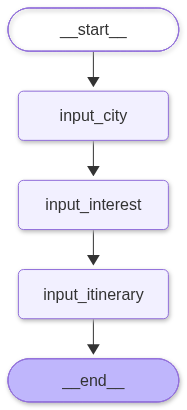

Initial Request: I want to paln a day trip

Please enter the city you want to visit for your day trip:
Your input:Haldia
Please enter your interest for the trip to : Haldia (comma-separated): 
Your input:mahisadal,river side
Creating an itinerary for: Haldia based on interests: mahisadal, river side 

Final Itinerary:
**Day‑Trip Itinerary – Haldia (Mahisadal & Riverside Focus)**  

- **7:00 AM – 8:00 AM**  
  *Start from your accommodation (or the nearest bus/auto stand).*  
  - Take a local taxi or auto‑rickshaw to **Mahisadal** (≈ 30 min drive).  

- **8:00 AM – 10:00 AM – Mahisadal Exploration**  
  - Visit the historic **Mahisadal Temple** (dedicated to Lord Shiva).  
  - Walk through the village lanes, chat with locals, and capture the rural charm.  
  - Quick tea/coffee break at a roadside stall (try the local “puchka” or “jalebi”).  

- **10:00 AM – 10:30 AM – Return to Haldia**  
  - Drive back to Haldia (≈ 30 min).  

- **10:30 AM – 12:00 PM – Haldia Riverfront Walk**  
  - St

/tmp/ipykernel_15750/3222178908.py:235: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8937820d7c075b2e6c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [2]:
!pip install langchain_core langchain_groq langchain_community langchain langgraph
import os
from typing import TypedDict,Annotated, List
from langgraph.graph import StateGraph, END
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.prompts import ChatMessagePromptTemplate
from langchain_core.runnables.graph import MermaidDrawMethod
from IPython.display import display, Image

import os
import importlib
import importlib.util
import langchain_core.exceptions as exc

# Locate the compiled cache
pyc_path = importlib.util.cache_from_source(exc.__file__)

# Delete stale bytecode
if os.path.exists(pyc_path):
    os.remove(pyc_path)
    print("Old bytecode cache deleted")

# Reload the module
importlib.invalidate_caches()
importlib.reload(exc)

# Verify
print("ModelRefusalError exists:", hasattr(exc, "ModelRefusalError"))

from langchain_core.exceptions import ModelRefusalError
print("Import successful!")

%pip install --force-reinstall --no-cache-dir "langchain-core==1.8.4" "langchain-groq==1.2.1"

from langchain_core.exceptions import ModelRefusalError
from langchain_groq import ChatGroq

print("Both imports successful!")

from langchain_groq import ChatGroq
from getpass import getpass

groq_api_key = getpass("Enter your Groq API key: ")

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=groq_api_key,
    temperature=0
)

result = llm.invoke("What is Multi AI Agent?")
print(result.content)


from typing import TypedDict, Annotated, List
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph.message import add_messages

class PlannerState(TypedDict):
    messages: Annotated[List[HumanMessage | AIMessage], add_messages]
    city: str
    interests: List[str]
    itinerary: str

from langchain_core.prompts import ChatPromptTemplate

itinerary_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful travel assistant. Create a day trip itinerary for {city} based on the user's interests: {interests}. Provide a brief, bulleted itinerary."),
    ("human", "Create an itinerary for my day trip."),
])

##Define agent function

def input_city(state: PlannerState) -> PlannerState:
    print("Please enter the city you want to visit for your day trip:")
    user_message = input("Your input:")
    return {
        **state,
        "city": user_message,
        "messages": state["messages"] + [HumanMessage(content=user_message)]
    }

def input_interest(state: PlannerState) -> PlannerState:
    print(f"Please enter your interest for the trip to : {state['city']} (comma-separated): ")
    user_message = input("Your input:")
    return {
        **state,
        "interests": [interest.strip() for interest in user_message.split(",")],
        "messages": state["messages"] + [HumanMessage(content=user_message)]
    }

def input_itinerary(state: PlannerState) -> PlannerState:
    print(f"Creating an itinerary for: {state['city']} based on interests: {', '.join(state['interests'])} ")
    response = llm.invoke(itinerary_prompt.format_messages(city=state['city'], interests=','.join(state['interests'])))
    print("\nFinal Itinerary:")
    print(response.content)
    return {
        **state,
        "itinerary": response.content,
        "messages": state["messages"] + [AIMessage(content=response.content)]
    }


 ##Create and Compile the Graph


from langgraph.graph import StateGraph, END

workflow = StateGraph(PlannerState)

# Added nodes without leading spaces and matched function names
workflow.add_node("input_city", input_city)
workflow.add_node("input_interest", input_interest)
workflow.add_node("input_itinerary", input_itinerary)

workflow.set_entry_point("input_city")
workflow.add_edge("input_city", "input_interest")
workflow.add_edge("input_interest", "input_itinerary")
workflow.add_edge("input_itinerary", END)

app = workflow.compile()

# Display the Graph Structure

display(
    Image(
        app.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API
        )
    )
)

# Define the travel_planner function before calling it
def travel_planner(user_request: str):
    print(f"Initial Request: {user_request}\n")
    state = {
        "messages": [HumanMessage(content=user_request)],
        "city": "",
        "interests": [],
        "itinerary": ""
    }
    for output in app.stream(state):
        pass

user_request = "I want to paln a day trip"
travel_planner(user_request)


import gradio as gr
from langchain_core.messages import HumanMessage, AIMessage

# IMPORTANT:
# Replace 'app' with the name of your compiled LangGraph workflow.
# Example: graph = workflow.compile()
graph = app


def generate_itinerary(city, interests, travel_style, duration, budget, extra_requirements):

    if not city.strip():
        return "Please enter a destination city."

    if not interests:
        return "Please select at least one travel interest."

    prompt = f"""
    Plan a personalized trip with the following details:

    Destination: {city}
    Interests: {', '.join(interests)}
    Travel style: {travel_style}
    Duration: {duration}
    Budget: {budget}
    Additional requirements: {extra_requirements}

    Generate a detailed itinerary including:
    - Places to visit
    - Daily activities
    - Food recommendations
    - Travel suggestions
    - Practical tips
    """

    try:
        initial_state = {
            "messages": [HumanMessage(content=prompt)],
            "city": city,
            "interests": interests,
            "itinerary": ""
        }

        # Execute your multi-agent LangGraph workflow
        result = graph.invoke(initial_state)

        # Get the itinerary from the final state
        itinerary = result.get("itinerary", "")

        # Fallback: retrieve the final AI response
        if not itinerary:
            messages = result.get("messages", [])

            for message in reversed(messages):
                if isinstance(message, AIMessage):
                    itinerary = message.content
                    break

        if not itinerary:
            return "The agents completed execution, but no itinerary was returned. Check your graph's final node."

        return itinerary

    except Exception as e:
        return f"Something went wrong: {str(e)}"


# ---------------- GRADIO INTERFACE ----------------

custom_css = """
.gradio-container {
    max-width: 1050px !important;
    margin: auto !important;
}

#main-title {
    text-align: center;
}

#generate-btn {
    background: #176B5B;
    color: white;
    font-weight: bold;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="emerald",
        secondary_hue="teal"
    ),
    css=custom_css,
    title="AI Travel Planner"
) as demo:

    gr.Markdown(
        """
        # ✈️ AI Travel Planner
        ### Your personal AI-powered travel companion

        Discover destinations, explore experiences, and generate
        personalized travel itineraries using Multi-Agent AI.
        """,
        elem_id="main-title"
    )

    gr.Markdown("---")

    with gr.Row():

        with gr.Column(scale=1):

            gr.Markdown("### 🌍 Plan Your Journey")

            city = gr.Textbox(
                label="Destination City",
                placeholder="e.g. Paris, Tokyo, Goa"
            )

            interests = gr.CheckboxGroup(
                choices=[
                    "Adventure",
                    "Food",
                    "History",
                    "Nature",
                    "Shopping",
                    "Beaches",
                    "Culture",
                    "Nightlife",
                    "Photography"
                ],
                label="Your Interests"
            )

            travel_style = gr.Radio(
                choices=[
                    "Relaxed",
                    "Balanced",
                    "Fast-paced"
                ],
                value="Balanced",
                label="Travel Style"
            )

            duration = gr.Dropdown(
                choices=[
                    "1-2 Days",
                    "3-5 Days",
                    "6-7 Days",
                    "1-2 Weeks"
                ],
                value="3-5 Days",
                label="Trip Duration"
            )

            budget = gr.Dropdown(
                choices=[
                    "Budget",
                    "Moderate",
                    "Luxury"
                ],
                value="Moderate",
                label="Travel Budget"
            )

            extra_requirements = gr.Textbox(
                label="Additional Requirements",
                placeholder="e.g. Vegetarian food, family-friendly places...",
                lines=3
            )

            generate_btn = gr.Button(
                "✨ Generate My Itinerary",
                variant="primary",
                elem_id="generate-btn"
            )

        with gr.Column(scale=1):

            gr.Markdown("### 🗺️ Your Personalized Itinerary")

            output = gr.Markdown(
                value="Your travel itinerary will appear here after generation.",
                height=500
            )

    gr.Markdown("---")

    gr.Markdown(
        """
        **Powered by:** Python · LangChain · LangGraph · Groq · Gradio

        *Intelligent travel planning through collaborative AI agents.*
        """
    )

    generate_btn.click(
        fn=generate_itinerary,
        inputs=[
            city,
            interests,
            travel_style,
            duration,
            budget,
            extra_requirements
        ],
        outputs=output
    )


# Launch the application
demo.launch(share=True)